In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

# Use numerical features available before the final exam
features = ["age", "Medu", "Fedu", "traveltime",
            "studytime", "failures", "famrel",
            "freetime", "goout", "Dalc", "Walc",
            "health", "absences"]

X = df[features].to_numpy(dtype=float)
y = df["G3"].to_numpy(dtype=float)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (395, 13)
y shape: (395,)


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 316
Testing examples: 79


In [3]:
m, n = X_train.shape

w = np.zeros(n)
b = 0.0

alpha = 0.01
iterations = 2000
cost_history = []

for i in range(iterations):
    predictions = X_train @ w + b
    errors = predictions - y_train

    dw = (X_train.T @ errors) / m
    db = np.sum(errors) / m

    w -= alpha * dw
    b -= alpha * db

    cost = np.sum(errors ** 2) / (2 * m)
    cost_history.append(cost)

print("Final cost:", cost_history[-1])
print("Weights:", w)
print("Bias:", b)

Final cost: 8.496104491609259
Weights: [-0.32819634  0.67622782 -0.22359382 -0.23816697  0.41540929 -1.42572158
  0.33143134  0.25552787 -0.53581267 -0.04645873  0.31819437 -0.22161245
  0.30889549]
Bias: 10.325949347843553


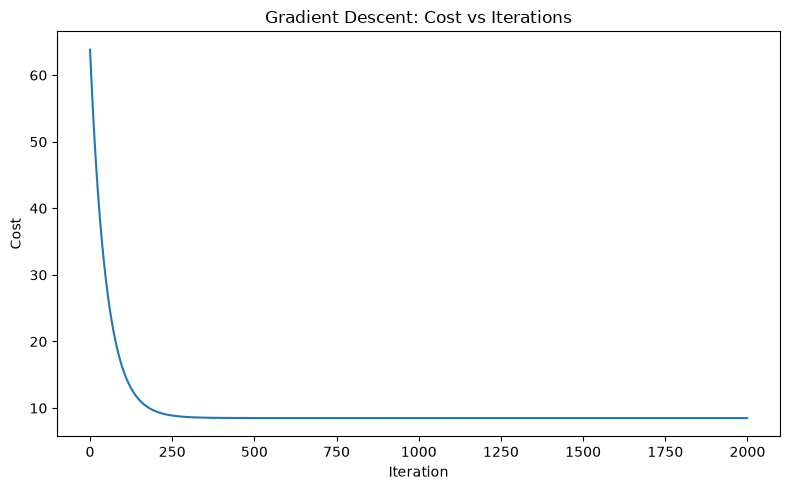

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(cost_history)
plt.title("Gradient Descent: Cost vs Iterations")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.tight_layout()
plt.show()

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = X_test @ w + b

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.3f}")

comparison = pd.DataFrame({
    "Actual grade": y_test[:10],
    "Predicted grade": np.round(y_pred[:10], 2)
})
display(comparison)

MAE:  3.49
RMSE: 4.25
R²:   0.118


,Actual grade,Predicted grade
0,10.0,5.37
1,12.0,8.77
2,5.0,8.98
3,10.0,11.11
4,9.0,7.11
5,13.0,9.93
6,18.0,11.41
7,6.0,10.49
8,0.0,10.83
9,14.0,11.78
